In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

from scipy.stats import pearsonr

In [3]:

#load cleaned data
pce_data = pd.read_csv("data/pce_data_clean.csv")
bg_data = pd.read_csv("data/bandgap_data_clean.csv")


In [4]:
S = ["Cs", "FA", "MA", "Pb", "Sn", "I", "Br", "Cl"]
layer_cols = ["Architecture", "ETL", "HTL", "Substrate", "Backcontact"]

In [5]:
X = pd.get_dummies(pce_data[S + ["Eg", "Area"] + layer_cols], columns=layer_cols, dtype=int)
y = pce_data["PCE"]

Xb = bg_data[S]
yb = bg_data["Eg"]

print(X.shape, Xb.shape)   # (635, 29) (588, 8)

(635, 29) (588, 8)


In [6]:
#splitting the PCE data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), "training rows,", len(X_test), "test rows")   # 508, 127

508 training rows, 127 test rows


In [7]:
#the scoring function for the model
def score(y_true, y_pred):
    r = pearsonr(y_true, y_pred)[0]                  # [0] = the r value ([1] is a p-value)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5  # square root of the mean squared error
    return r, rmse

In [9]:
#tuning the random forest model with grid search

param_grid = {
    "n_estimators":     [200, 500],
    "max_depth":        [None, 10, 20],
    "min_samples_leaf": [1, 2, 4],
    "max_features":     [1.0, "sqrt", 0.5],
}

rf = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid,
    cv=5,                                   # 5-fold cross-validation
    scoring="neg_root_mean_squared_error",  # pick the settings with the lowest RMSE
)
rf.fit(X_train, y_train)

print("Best settings:", rf.best_params_)
rf_best = rf.best_estimator_            # the forest refitted with the best settings

r, rmse = score(y_test, rf_best.predict(X_test))
print(f"Tuned random forest:  r = {r:.2f},  RMSE = {rmse:.2f} %")

Best settings: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 500}
Tuned random forest:  r = 0.84,  RMSE = 2.99 %


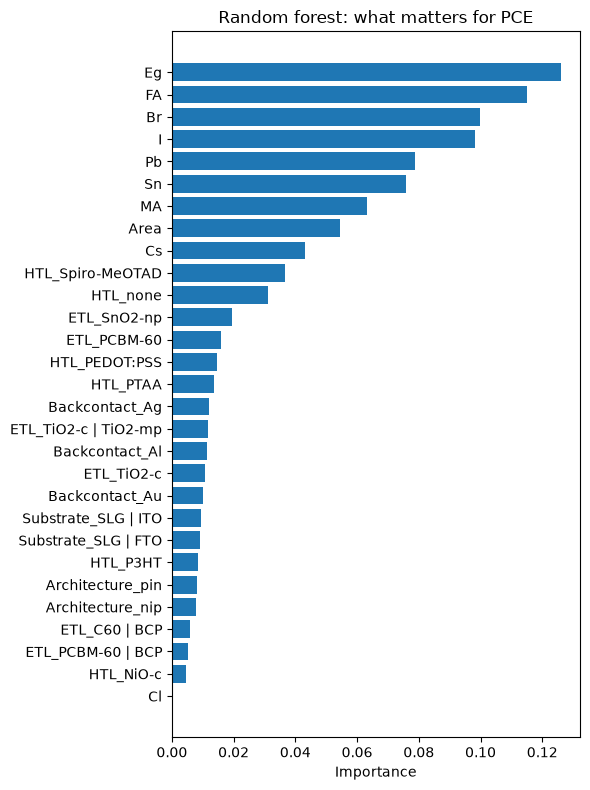

In [10]:
#finding feature importance for the random forest model

importance = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(6, 8))
ax.barh(importance.index, importance.values)
ax.set(xlabel="Importance", title="Random forest: what matters for PCE")
plt.tight_layout()
plt.show()